<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/diabetes_regression_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # 회귀는 얼마나 가깝게 맞혔냐를 채점해야 함.

# 1. 데이터 불러오기
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/diabetes.csv')

In [5]:
# 2. Outcome 제거 및 결측치(0) 처리
df = df.drop("Outcome", axis=1)        # 분류용 정답이므로 회귀에서는 사용하지 않음.
df = df[df["BMI"] > 0]             # BMI 0은 측정 누락이므로 제거
df = df.sort_index().reset_index(drop=True)

print(df.index)

RangeIndex(start=0, stop=757, step=1)


In [6]:
# 3. 입력 / 정답 분리
X = df.drop("BMI", axis=1).values      # 입력: BMI를 뺀 7개 열
y = df["BMI"].values                   # 정답: BMI (연속값)

# 4. 학습 / 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. 데이터 정규화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
# 6. 모델 생성
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(7,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(1))

# 7. 모델 설정
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [8]:
# 8. 모델 구조 출력
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 801 (3.13 KB)

 Trainable params: 801 (3.13 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# 9. 모델 학습
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 1059.9812 - mae: 31.7918 - val_loss: 991.1671 - val_mae: 30.6553
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1028.4019 - mae: 31.2975 - val_loss: 958.3311 - val_mae: 30.1162
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 987.5800 - mae: 30.6443 - val_loss: 914.8162 - val_mae: 29.3848
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 931.9889 - mae: 29.7360 - val_loss: 855.4030 - val_mae: 28.3585
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 858.0125 - mae: 28.4762 - val_loss: 779.2459 - val_mae: 26.9852
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 764.7529 - mae: 26.8135 - val_loss: 687.2350 - val_mae: 25.2141
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 654.9662 - mae: 24.6914 - val_loss: 582.7874 - val_mae: 23.0277
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 536.0259 - mae: 22.1179 - val_loss: 470.7509 - val_mae: 20.4004
Epoch 

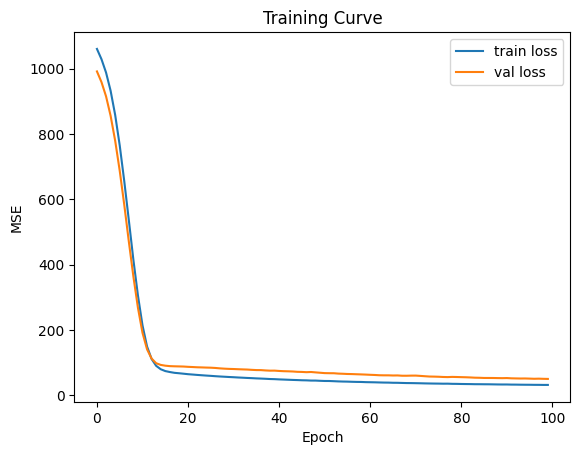

In [10]:
# 10. 학습 곡선 시각화
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.title("Training Curve")
plt.show()

In [11]:
# 11. 테스트 데이터 예측
y_pred = model.predict(X_test).flatten()

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [12]:
# 12. 성능 평가
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE  =", mae)
print("RMSE =", rmse)
print("R2   =", r2)

MAE  = 4.464762045207776
RMSE = 5.649974719766437
R2   = 0.21378019497720235


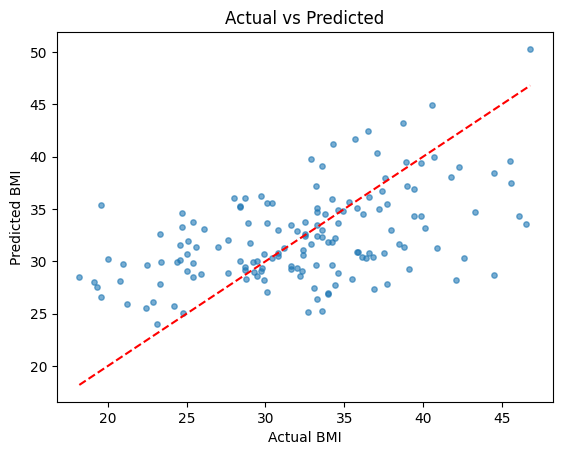

In [13]:
# 13. 실제값 vs 예측값 시각화
plt.scatter(y_test, y_pred, s=15, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")  # 완벽 예측선
plt.xlabel("Actual BMI")
plt.ylabel("Predicted BMI")
plt.title("Actual vs Predicted")
plt.show()